In [15]:
%conda install pandas matplotlib seaborn scikit-learn sqlite3

2 channel Terms of Service accepted
Channels:
 - defaults
Platform: linux-64
Solving environment: failed

PackagesNotFoundError: The following packages are not available from current channels:

  - sqlite3

Current channels:

  - defaults

To search for alternate channels that may provide the conda package you're
looking for, navigate to

    https://anaconda.org

and use the search bar at the top of the page.



Note: you may need to restart the kernel to use updated packages.


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

pd.set_option('display.max_columns', None)
sns.set_style("whitegrid")

column_names = [
    "checking_status", "duration", "credit_history", "purpose", "credit_amount",
    "savings_status", "employment", "installment_rate", "personal_status_sex", 
    "other_debtors", "residence_since", "property", "age", "other_installment_plans", 
    "housing", "existing_credits", "job", "num_dependents", "telephone", 
    "foreign_worker", "class"
]

file_path = 'data/german.data'

try:
    df = pd.read_csv(file_path, sep=r'\s+', header=None, names=column_names)
    print("Data loaded successfully from local file.")
except Exception as e:
    print(f"Error loading data: {e}")

print("\n--- Dataset Information ---")
print(df.info())

print("\n--- First 5 rows ---")
print(df.head())

print("\n--- Missing Values Check ---")
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])

if missing_values.sum() == 0:
    print("No missing values found.")
else:
    print("Missing values detected.")

df['target'] = df['class'].map({1: 0, 2: 1})
df = df.drop(columns=['class'])

print("\nTarget variable transformed: 0 = Good, 1 = Bad")

Data loaded successfully from local file.

--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   checking_status          1000 non-null   object
 1   duration                 1000 non-null   int64 
 2   credit_history           1000 non-null   object
 3   purpose                  1000 non-null   object
 4   credit_amount            1000 non-null   int64 
 5   savings_status           1000 non-null   object
 6   employment               1000 non-null   object
 7   installment_rate         1000 non-null   int64 
 8   personal_status_sex      1000 non-null   object
 9   other_debtors            1000 non-null   object
 10  residence_since          1000 non-null   int64 
 11  property                 1000 non-null   object
 12  age                      1000 non-null   int64 
 13  other_installment_plans

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

pd.set_option('display.max_columns', None)
sns.set_style("whitegrid")

column_names = [
    "checking_status", "duration", "credit_history", "purpose", "credit_amount",
    "savings_status", "employment", "installment_rate", "personal_status_sex", 
    "other_debtors", "residence_since", "property", "age", "other_installment_plans", 
    "housing", "existing_credits", "job", "num_dependents", "telephone", 
    "foreign_worker", "class"
]

file_path = 'data/german.data'

try:
    df = pd.read_csv(file_path, sep=r'\s+', header=None, names=column_names)
    print("Data loaded successfully from local file.")
except Exception as e:
    print(f"Error loading data: {e}")

df['target'] = df['class'].map({1: 0, 2: 1})
df = df.drop(columns=['class'])

print("\n--- 1. Numerical Statistics ---")
print(df.describe())

print("\n--- 2. Categorical Features Analysis ---")
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
for col in categorical_cols:
    print(f"\nFeature: {col}")
    print(df[col].value_counts())

print("\n--- 3. Encoding Categorical Features (Label Encoding) ---")
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le
    print(f"Encoded {col}. Classes: {le.classes_}")

print("\n--- Data after Encoding (First 5 rows) ---")
print(df.head())

print("\n--- Data Types after Encoding ---")
print(df.dtypes)

Data loaded successfully from local file.

--- 1. Numerical Statistics ---
          duration  credit_amount  installment_rate  residence_since  \
count  1000.000000    1000.000000       1000.000000      1000.000000   
mean     20.903000    3271.258000          2.973000         2.845000   
std      12.058814    2822.736876          1.118715         1.103718   
min       4.000000     250.000000          1.000000         1.000000   
25%      12.000000    1365.500000          2.000000         2.000000   
50%      18.000000    2319.500000          3.000000         3.000000   
75%      24.000000    3972.250000          4.000000         4.000000   
max      72.000000   18424.000000          4.000000         4.000000   

               age  existing_credits  num_dependents       target  
count  1000.000000       1000.000000     1000.000000  1000.000000  
mean     35.546000          1.407000        1.155000     0.300000  
std      11.375469          0.577654        0.362086     0.458487  
min 

Data loaded successfully from local file.

--- 1. Numerical Statistics ---
          duration  credit_amount  installment_rate  residence_since  \
count  1000.000000    1000.000000       1000.000000      1000.000000   
mean     20.903000    3271.258000          2.973000         2.845000   
std      12.058814    2822.736876          1.118715         1.103718   
min       4.000000     250.000000          1.000000         1.000000   
25%      12.000000    1365.500000          2.000000         2.000000   
50%      18.000000    2319.500000          3.000000         3.000000   
75%      24.000000    3972.250000          4.000000         4.000000   
max      72.000000   18424.000000          4.000000         4.000000   

               age  existing_credits  num_dependents       target  
count  1000.000000       1000.000000     1000.000000  1000.000000  
mean     35.546000          1.407000        1.155000     0.300000  
std      11.375469          0.577654        0.362086     0.458487  
min 

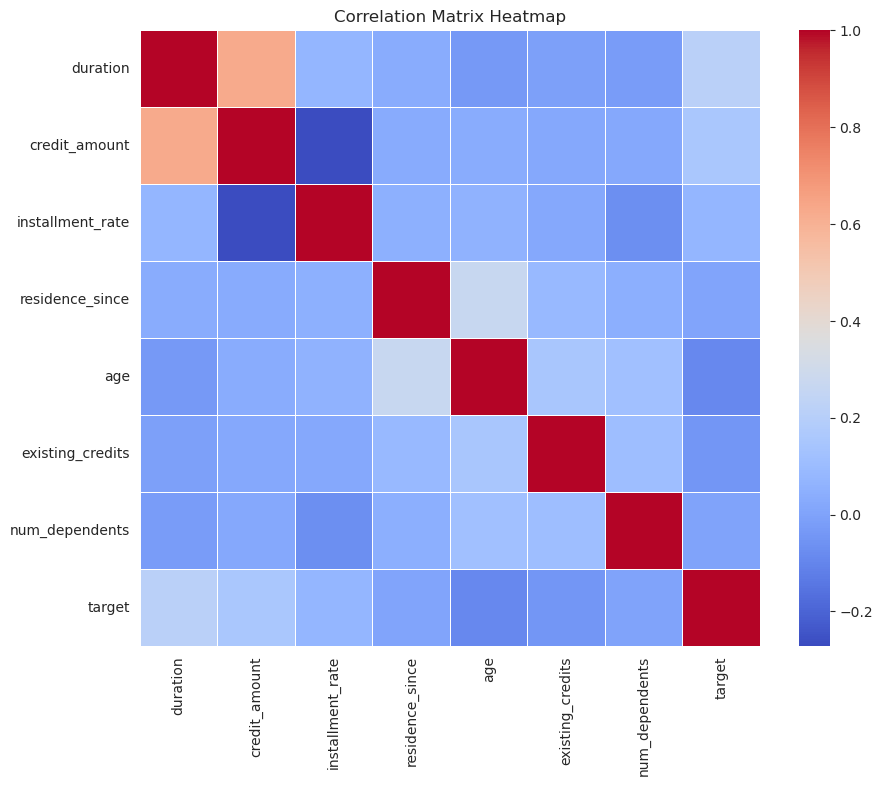

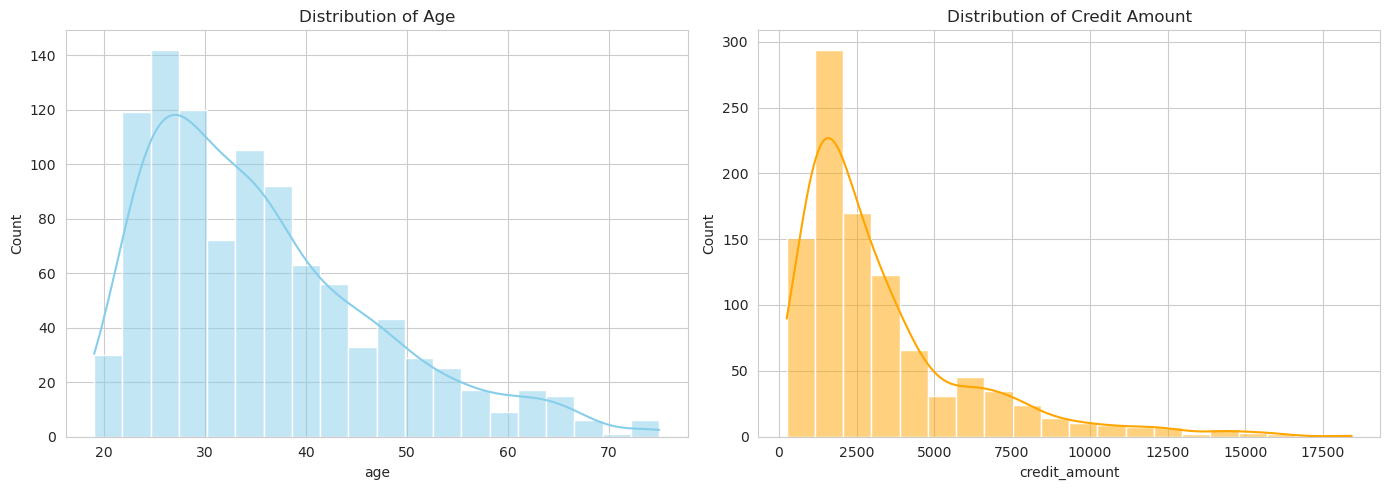

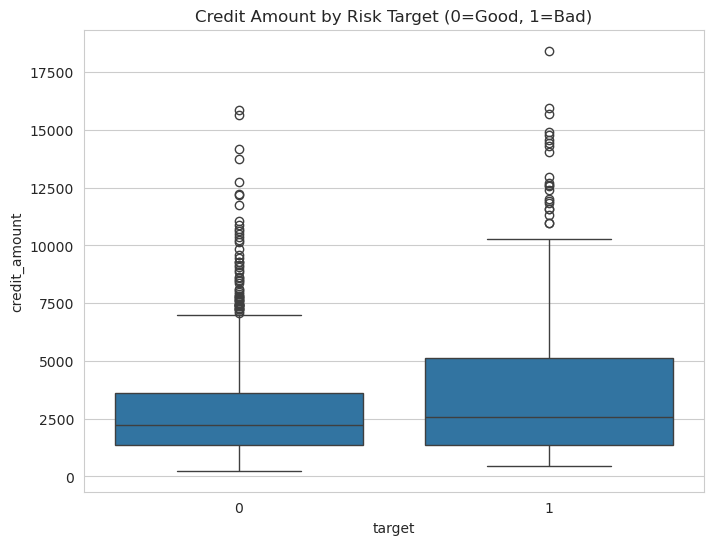

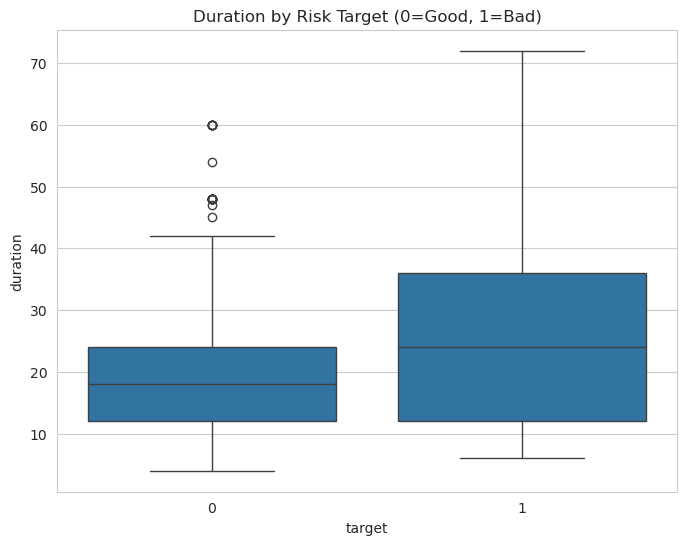


--- Aggregated Statistics by Target (Risk) ---
        credit_amount   duration        age
target                                     
0         2985.457143  19.207143  36.224286
1         3938.126667  24.860000  33.963333

--- Aggregated Statistics by Housing Type ---
housing
0    3122.553073
1    3060.939691
2    4906.212963
Name: credit_amount, dtype: float64


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

pd.set_option('display.max_columns', None)
sns.set_style("whitegrid")

column_names = [
    "checking_status", "duration", "credit_history", "purpose", "credit_amount",
    "savings_status", "employment", "installment_rate", "personal_status_sex", 
    "other_debtors", "residence_since", "property", "age", "other_installment_plans", 
    "housing", "existing_credits", "job", "num_dependents", "telephone", 
    "foreign_worker", "class"
]

file_path = 'data/german.data'

try:
    df = pd.read_csv(file_path, sep=r'\s+', header=None, names=column_names)
    print("Data loaded successfully from local file.")
except Exception as e:
    print(f"Error loading data: {e}")

df['target'] = df['class'].map({1: 0, 2: 1})
df = df.drop(columns=['class'])

print("\n--- 1. Numerical Statistics ---")
print(df.describe())

print("\n--- 2. Categorical Features Analysis ---")
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
for col in categorical_cols:
    print(f"\nFeature: {col}")
    print(df[col].value_counts())

print("\n--- 3. Encoding Categorical Features (Label Encoding) ---")
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le
    print(f"Encoded {col}. Classes: {le.classes_}")

print("\n--- Data after Encoding (First 5 rows) ---")
print(df.head())

print("\n--- Data Types after Encoding ---")
print(df.dtypes)

# --- 4. Visual Analysis & Correlations ---

# 4.1. Correlation Matrix & Heatmap
numeric_columns = [
    'duration', 'credit_amount', 'installment_rate', 'residence_since', 
    'age', 'existing_credits', 'num_dependents', 'target'
]

plt.figure(figsize=(10, 8))
correlation_matrix = df[numeric_columns].corr()
# Heatmap
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix Heatmap')
plt.show()

# 4.2. Histograms (Distributions)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Age distribution
sns.histplot(df['age'], bins=20, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Age')

# Credit amount distribution
sns.histplot(df['credit_amount'], bins=20, kde=True, ax=axes[1], color='orange')
axes[1].set_title('Distribution of Credit Amount')

plt.tight_layout()
plt.show()

# 4.3. Boxplots (Outliers & Relationships)
# Credit amount - Risk (Target: 0=Good, 1=Bad)
plt.figure(figsize=(8, 6))
sns.boxplot(x='target', y='credit_amount', data=df)
plt.title('Credit Amount by Risk Target (0=Good, 1=Bad)')
plt.show()

# Credit duration - Risk (Target: 0=Good, 1=Bad)
plt.figure(figsize=(8, 6))
sns.boxplot(x='target', y='duration', data=df)
plt.title('Duration by Risk Target (0=Good, 1=Bad)')
plt.show()

# --- 5. Data Aggregation (Groupby) ---
print("\n--- Aggregated Statistics by Target (Risk) ---")
agg_data = df.groupby('target')[['credit_amount', 'duration', 'age']].mean()
print(agg_data)

# housing: 0 - rent, 1 - own, 2 - for free
print("\n--- Aggregated Statistics by Housing Type ---")
agg_housing = df.groupby('housing')['credit_amount'].mean()
print(agg_housing)

In [17]:
# --- 6. SQL Database Operations ---
print("\n--- 6. SQL Database Operations ---")

# 1. Connect to SQLite database
db_name = 'german_credit.db'
conn = sqlite3.connect(db_name)
cursor = conn.cursor()

# 2. Write the DataFrame to the SQL table
try:
    df.to_sql('credits', conn, if_exists='replace', index=False)
    print(f"Data successfully saved to '{db_name}' in table 'credits'.")
except Exception as e:
    print(f"Error saving to SQL: {e}")

# 3. Execute SQL Queries

# Query A: Select high credit amounts (> 10000) - Simple Selection
print("\n[SQL Query 1] High Credit Amounts (> 10000 DM) - First 5 rows:")
query1 = """
SELECT age, credit_amount, duration, target 
FROM credits 
WHERE credit_amount > 10000 
LIMIT 5
"""
try:
    results1 = pd.read_sql_query(query1, conn)
    print(results1)
except Exception as e:
    print(e)

# Query B: Average Credit Amount by Risk (Target) - Aggregation
print("\n[SQL Query 2] Average Credit Amount by Risk (Target 0=Good, 1=Bad):")
query2 = """
SELECT target, AVG(credit_amount) as avg_credit, COUNT(*) as count
FROM credits 
GROUP BY target
"""
try:
    results2 = pd.read_sql_query(query2, conn)
    print(results2)
except Exception as e:
    print(e)

# Query C: Credit statistics by Job Type - Grouping & Aggregation
print("\n[SQL Query 3] Max and Min Credit Amount by Job Type:")
query3 = """
SELECT job, MAX(credit_amount) as max_credit, MIN(credit_amount) as min_credit
FROM credits 
GROUP BY job
"""
try:
    results3 = pd.read_sql_query(query3, conn)
    print(results3)
except Exception as e:
    print(e)

# Close connection
conn.close()
print("\nDatabase connection closed.")


--- 6. SQL Database Operations ---
Data successfully saved to 'german_credit.db' in table 'credits'.

[SQL Query 1] High Credit Amounts (> 10000 DM) - First 5 rows:
   age  credit_amount  duration  target
0   44          12579        24       1
1   25          14421        48       1
2   47          12612        36       1
3   58          15945        54       1
4   39          11938        24       1

[SQL Query 2] Average Credit Amount by Risk (Target 0=Good, 1=Bad):
   target   avg_credit  count
0       0  2985.457143    700
1       1  3938.126667    300

[SQL Query 3] Max and Min Credit Amount by Job Type:
   job  max_credit  min_credit
0    0       14555         609
1    1       11998         250
2    2       15945         338
3    3       18424         629

Database connection closed.
